# Consulta Prévia contracts

Contracts whose `tipo_procedimento` is a Consulta Prévia variant: `Consulta Prévia` (67 826), `Consulta Prévia Simplificada` (1 218) and the Lei 30/2021 art. 7.º variant (20).

**Rule:** `tipo_procedimento` lowercased and accent-folded `.str.starts_with("consulta previa")`. Reference: **69,064 rows** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=409,344  cols=20
disregarded 1,484 contracts with |preco_contratual| < €10 (0.36%); kept 407,860
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 407858 │
│ name                   ┆ 2      │
└────────────────────────┴────────┘


In [3]:
CPREV_EXPR = (
    pl.col("tipo_procedimento")
    .str.to_lowercase()
    .str.replace_all("ú", "u")
    .str.replace_all("é", "e")
    .str.starts_with("consulta previa")
)
contracts["tipo_procedimento"].value_counts(sort=True)

tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",178077
"""Consulta Prévia""",67709
"""Concurso público""",63033
"""Ao abrigo de acordo-quadro (ar…",55195
"""Contratação excluída II""",27226
"""Ao abrigo de acordo-quadro (ar…",10459
"""Setores especiais – isenção pa…",2244
"""Ajuste direto simplificado ao …",1531
"""Consulta Prévia Simplificada""",1218


In [4]:
proc = contracts.filter(CPREV_EXPR)
print(f"Consulta Prévia rows: {proc.height:,}  share by count: {proc.height / contracts.height:.1%}  "
      f"share by value: {proc['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = proc["tipo_procedimento"].value_counts(sort=True)
display(variants)
assert variants["count"].sum() == proc.height and proc.height < contracts.height
variants

n_before = contracts_all.filter(CPREV_EXPR).height
n_after = proc.height
assert n_after <= n_before
print(f"{n_before:,} before the €{MIN_VALUE:g} flag, {n_after:,} after "
      f"({n_before - n_after:,} flagged below the threshold)")

Consulta Prévia rows: 68,947  share by count: 16.9%  share by value: 6.5%


tipo_procedimento,count
str,u32
"""Consulta Prévia""",67709
"""Consulta Prévia Simplificada""",1218
"""Consulta prévia ao abrigo do a…",20


In [5]:
# Effect of disregarding contracts with |value| below €10 on Consulta Prévia.
before = contracts_all.filter(CPREV_EXPR)
display(value_impact(before, proc))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",69064.0,68947.0,-117.0,-0.17
"""mean_value""",35485.742848,35545.959642,60.216794,0.17
"""median_value""",23216.43,23290.0,73.57,0.32
"""total_value""",2.4508e9,2.4508e9,-64.610001,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 283 of 68,947


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
20.0,45.0,180.0,365.0,730.0,15.7,39.52,126.62,577.42,1599.34


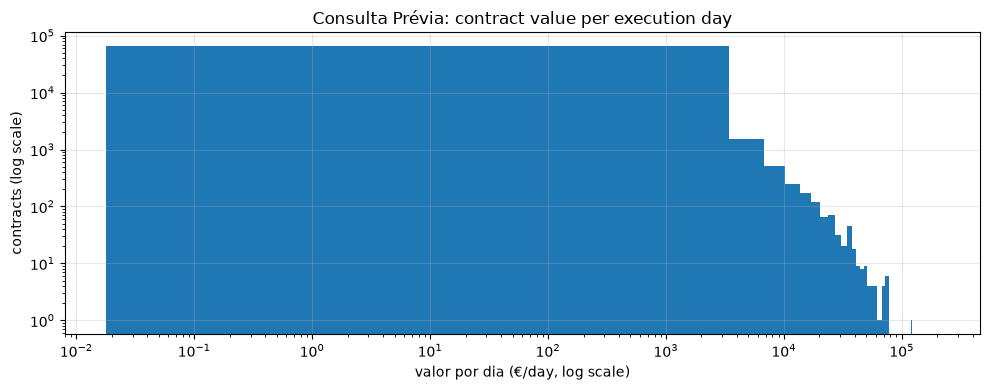

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = proc
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    proc.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""91-365 d""",31925,18004.24,63.76,1.0245e9
"""1-30 d""",14091,19541.4,1067.24,3.90922903e8
"""31-90 d""",12682,32870.94,533.35,5.82314321e8
"""366-3650 d""",9966,37099.2,42.56,4.49226165e8


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(proc, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))

shape: (2, 2)
┌───────────────────────┬───────┐
│ adjudicatarios_status ┆ count │
│ ---                   ┆ ---   │
│ str                   ┆ u32   │
╞═══════════════════════╪═══════╡
│ YES                   ┆ 62102 │
│ NO_NIF                ┆ 6981  │
└───────────────────────┴───────┘
shape: (2, 2)
┌───────────────────────────┬───────┐
│ adjudicatarios_key_source ┆ count │
│ ---                       ┆ ---   │
│ str                       ┆ u32   │
╞═══════════════════════════╪═══════╡
│ nipc                      ┆ 62102 │
│ name                      ┆ 6981  │
└───────────────────────────┴───────┘


In [9]:
by_adjudicante = (
    proc.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(proc, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Consulta Prévia count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Consulta Prévia value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))

Top 20 adjudicantes by Consulta Prévia count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""511228848""",927,1.5645e7,"""Serviço de Saúde da Região Aut…"
"""508481287""",621,9.7408e6,"""Unidade Local de Saúde de Sant…"
"""510103448""",465,5.9399e6,"""Unidade Local de Saúde de Coim…"
"""500051062""",411,6.2618e6,"""Município de Sintra"""
"""501413197""",376,1.0380e7,"""Universidade do Porto"""
"""506663264""",341,1.6272e7,"""Município de Vila Nova de Fama…"
"""501442600""",340,7.9163e6,"""Instituto do Emprego e da Form…"
"""506361438""",317,3.1125e6,"""Instituto Português de Oncolog…"
"""500745943""",314,1.6523e7,"""Município de Oeiras"""



Top 20 adjudicantes by Consulta Prévia value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""505187531""",188,2.5192e7,"""Município de Cascais"""
"""503933813""",163,2.2713e7,"""Infraestruturas de Portugal, S…"
"""506614913""",295,2.0687e7,"""Município de Vila Franca de Xi…"
"""511010435""",106,2.0126e7,"""EEM - Empresa de Electricidade…"
"""506173968""",274,1.9591e7,"""Município do Seixal"""
"""500745943""",314,1.6523e7,"""Município de Oeiras"""
"""506663264""",341,1.6272e7,"""Município de Vila Nova de Fama…"
"""500051070""",287,1.6127e7,"""Município de Lisboa"""
"""511228848""",927,1.5645e7,"""Serviço de Saúde da Região Aut…"


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(proc.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")

Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""508831989""",413,4.8170e6,"""nipc""","""OLMAR - Artigos de Papelaria, …"
"""510238351""",225,1.7959e6,"""nipc""","""Márcio Moreira Rocha Uni-pesso…"
"""504615947""",224,7.5694e6,"""nipc""","""MEO - Serviços de Comunicações…"
"""500271518""",188,2979482.1,"""nipc""","""Sogenave - Sociedade Geral de …"
"""500853975""",179,906597.46,"""nipc""","""Manuel Rui Azinhais Nabeiro, U…"
"""504100327""",155,2.7213e6,"""nipc""","""PRN Informática"""
"""503183997""",152,1.8512e6,"""nipc""","""Lactogal-Produtos Alimentares,…"
"""503653179""",146,4.4790e6,"""nipc""","""NAUTILUS, S.A"""
"""505042037""",136,1.3859e6,"""nipc""","""SUMOL+COMPAL Marcas, SA"""



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""500697370""",104,1.5399e7,"""nipc""","""PETROGAL, S.A."""
"""508170710""",5,1.0720e7,"""nipc""","""PSG - SEGURANÇA PRIVADA, S.A."""
"""504615947""",224,7.5694e6,"""nipc""","""MEO - Serviços de Comunicações…"
"""500918880""",100,6.4758e6,"""nipc""","""Fidelidade Companhia de Seguro…"
"""510728189""",110,6.4521e6,"""nipc""","""CLARANET II SOLUTIONS, S.A."""
"""500097488""",5,6.1660e6,"""nipc""","""Teixeira Duarte - Engenharia e…"
"""513564772""",13,5043714.6,"""nipc""","""SOMAFLOOR, LDA."""
"""502124083""",4,4.8639e6,"""nipc""","""Iberdrola Clientes Portugal Un…"
"""508831989""",413,4.8170e6,"""nipc""","""OLMAR - Artigos de Papelaria, …"


awardee entries keyed by name fallback: 6,981 of 69,083 (10.1%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = proc.group_by("adjudicante_key", "adjudicante_name").len()
new = proc.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    proc.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)

adjudicante rows: 5,667 (key, name spelling) -> 4,381 keys
adjudicatario rows: 33,871 (key, name) -> 24,030 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""501442600""",38,340
"""501413197""",32,376
"""501559094""",10,237
"""600012662""",10,219
"""502530863""",8,26


shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 68947.0      │
│ null_count ┆ 0.0          │
│ mean       ┆ 35545.959642 │
│ std        ┆ 80982.155005 │
│ min        ┆ 10.0         │
│ 25%        ┆ 9600.0       │
│ 50%        ┆ 23290.0      │
│ 75%        ┆ 47035.2      │
│ max        ┆ 1.0685e7     │
└────────────┴──────────────┘


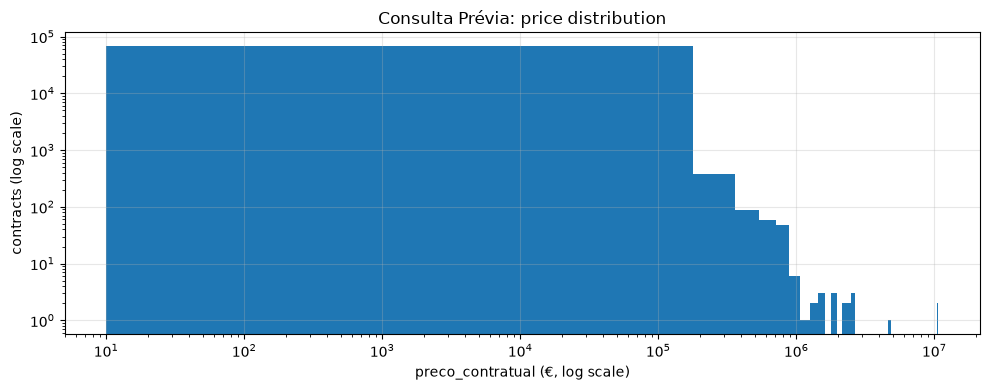

contracts above €5,000: 59,246
contracts above €20,000: 37,521
contracts above €75,000: 4,362


In [12]:
prices = proc["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")

concorrentes reported: 79.3%
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 54654.0  │
│ null_count ┆ 0.0      │
│ mean       ┆ 2.326124 │
│ std        ┆ 3.16846  │
│ min        ┆ 1.0      │
│ 25%        ┆ 1.0      │
│ 50%        ┆ 2.0      │
│ 75%        ┆ 3.0      │
│ max        ┆ 54.0     │
└────────────┴──────────┘


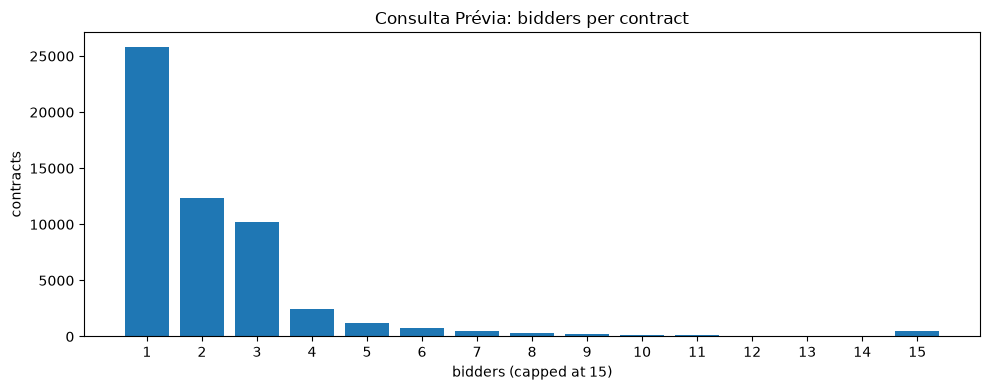

Single-bidder share among reported: 47.3%


TipoCriterioAdjudicacao,count
str,u32
"""Monofator""",63362
"""Multifator""",5582
"""Preço ou custo""",2
"""Melhor relação qualidade – pre…",1


tipo_procedimento,n_contracts,total_value,median_bidders
str,u32,f64,f64
"""Consulta Prévia""",67709,2.2360e9,2.0
"""Consulta Prévia Simplificada""",1218,2.1228e8,2.0
"""Consulta prévia ao abrigo do a…",20,2.4807e6,2.0


In [13]:
# Competition: `concorrentes` is a "\n"-separated list of "NIPC-name" bidders (null = not reported).
proc = proc.with_columns(
    pl.col("concorrentes").str.split("\n").list.eval(pl.element().str.strip_chars().filter(pl.element() != "")).list.len().alias("n_concorrentes")
)
print(f"concorrentes reported: {proc['concorrentes'].is_not_null().mean():.1%}")
print(proc["n_concorrentes"].drop_nulls().describe())
fig, ax = plt.subplots()
counts = proc["n_concorrentes"].drop_nulls().clip(upper_bound=15).value_counts().sort("n_concorrentes")
ax.bar(counts["n_concorrentes"].cast(pl.String), counts["count"])
ax.set_xlabel("bidders (capped at 15)")
ax.set_ylabel("contracts")
ax.set_title("Consulta Prévia: bidders per contract")
plt.tight_layout()
plt.show()
print("Single-bidder share among reported:", f"{(proc['n_concorrentes'] == 1).sum() / proc['n_concorrentes'].drop_nulls().len():.1%}")
display(proc["TipoCriterioAdjudicacao"].value_counts(sort=True))

# Sub-split by variant: standard vs simplified vs Lei 30/2021
display(proc.group_by("tipo_procedimento").agg(
    pl.len().alias("n_contracts"),
    pl.col("preco_contratual").sum().round(2).alias("total_value"),
    pl.col("n_concorrentes").median().alias("median_bidders"),
).sort("n_contracts", descending=True))

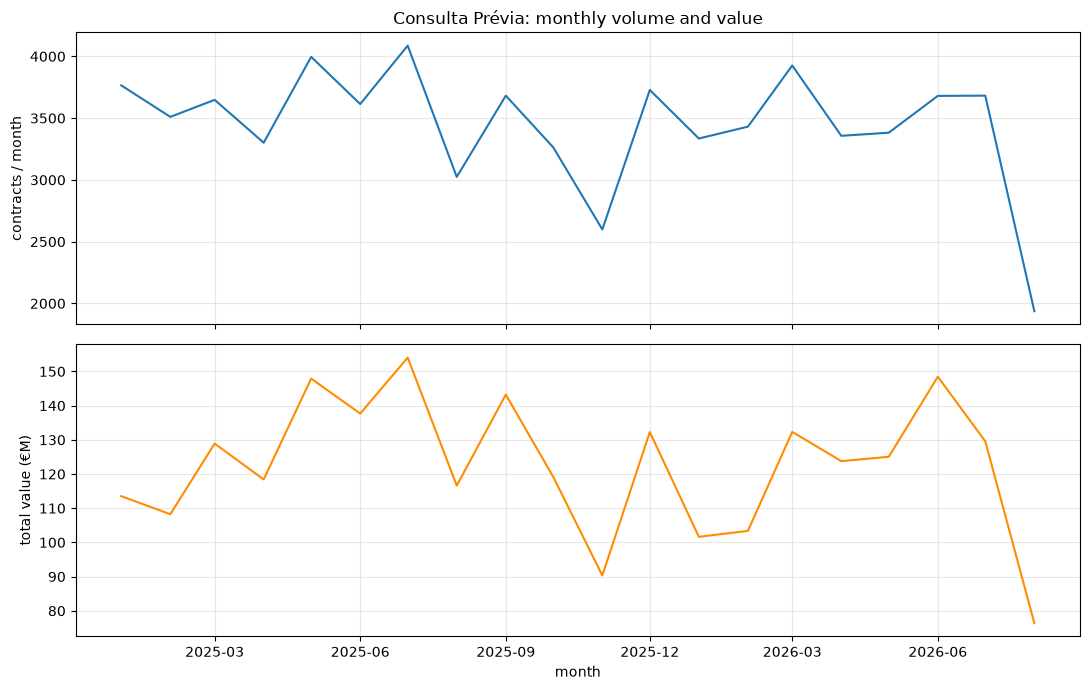

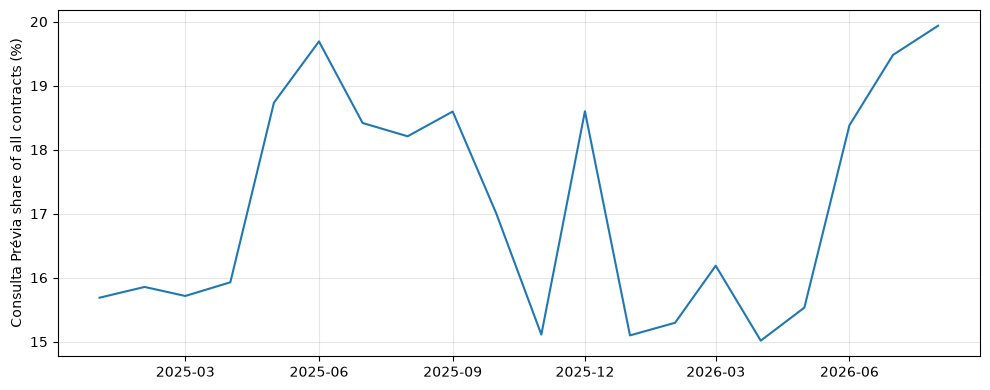

In [14]:
consulta_previa_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        CPREV_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(CPREV_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = consulta_previa_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Consulta Prévia: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(consulta_previa_monthly["month"], consulta_previa_monthly["share"] * 100)
ax.set_ylabel("Consulta Prévia share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
proc.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)

idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
15338186,"""REN Atlântico - Terminal de GN…",1.0685e7,"""Consulta Prévia""",2026-04-01,"""PC-2025-000882 - Fornecimento …"
11180375,"""Município de Cascais""",1.0570e7,"""Consulta Prévia""",2025-01-21,"""Aquisição de serviços de vigil…"
11942460,"""REN - Serviços, S. A.""",4.7981e6,"""Consulta Prévia""",2025-03-21,"""PC-2024-000870 - Fornecimento …"
11361869,"""EMACOM - TELECOMUNICAÇÕES DA M…",2.6049e6,"""Consulta Prévia""",2025-03-20,"""Empreitada de obras de constru…"
11486867,"""Infraestruturas de Portugal""",2.5997e6,"""Consulta Prévia""",2025-06-05,"""Empreitada A21 - KM12+480. REP…"
12183495,"""EEM - Empresa De Electricidade…",2.5436e6,"""Consulta Prévia""",2025-12-22,"""O contrato compreende o projet…"
11464803,"""Município de Setúbal""",2.4681e6,"""Consulta Prévia""",2025-04-24,"""BNAUT - ARRONCHES JUNQUEIRO"""
15320453,"""REN - Serviços, SA""",2.4611e6,"""Consulta Prévia""",2026-03-24,"""PC-2025-000547 - Subscrições e…"
13125209,"""Metropolitano de Lisboa, EPE""",2.2785e6,"""Consulta Prévia""",2026-01-22,"""Aquisição de Serviços de Segur…"


## Commentary and limitations

- `Ano` covers 2025–2026 only; edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`) and may over- or under-merge; see `key_source`. Dirty NIPCs stay separate keys.
- Very large values may be outliers or data-entry errors.
- Consulta Prévia invites a limited set of firms, so `concorrentes` reflects invited/bidding firms as reported.
- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.